# 11장. 분류 분석 (1) 로지스틱 회귀 분석을 이용한 유방암 진단 프로젝트

# 3. 데이터 준비 및 탐색

In [ ]:
import warnings
warnings.filterwarnings(action='ignore')

In [3]:
import numpy as np
from sklearn.metrics import roc_auc_score

# 1. 가상의 데이터 준비
# 실제 정답지 (0: Negative, 1: Positive)
y_true = np.array([0, 0, 1, 1, 0, 1, 1, 0])

# 2. 모델이 예측한 '확률(Probability)' 데이터 준비
# 보통 학습된 모델의 .predict_proba() 메서드를 사용해 추출한 '1(Positive)이 될 확률값'을 사용합니다.
y_scores = np.array([0.1, 0.4, 0.35, 0.8, 0.2, 0.9, 0.7, 0.6])

# 3. AUC 스코어 계산
# 첫 번째 파라미터에는 '실제 정답(y_true)'을, 두 번째 파라미터에는 '예측 확률(y_score)'을 넣습니다.
auc = roc_auc_score(y_true, y_scores)

print(f"ROC AUC 스코어: {auc:.4f}")

ROC AUC 스코어: 0.8750


In [4]:
import statsmodels.api as sm
import pandas as pd
import numpy as np
sales = [1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0]
price = [1500, 2000, 5000, 3000, 3500, 2500, 4000, 4500, 3000,\
4500, 4000, 4500, 5500, 6500, 5000, 3500, 7000]
data = {'sales': sales, 'price': price}
df = pd.DataFrame(data)
logis = sm.Logit.from_formula('sales ~ price', data=df).fit( )
print(logis.summary( ))
print('OR')
print(np.exp(logis.params))

Optimization terminated successfully.
         Current function value: 0.430873
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                  sales   No. Observations:                   17
Model:                          Logit   Df Residuals:                       15
Method:                           MLE   Df Model:                            1
Date:                Thu, 25 Jun 2026   Pseudo R-squ.:                  0.3768
Time:                        14:29:09   Log-Likelihood:                -7.3248
converged:                       True   LL-Null:                       -11.754
Covariance Type:            nonrobust   LLR p-value:                  0.002917
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      6.5752      3.300      1.993      0.046       0.108      13.042
price         -0.0016      0.

### (1) 데이터 준비하기

In [5]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer

In [6]:
b_cancer = load_breast_cancer()

### (2) 데이터 탐색하기

### 재현율
### 정밀도
### f1점수(조화 평균)

In [7]:
print(b_cancer.DESCR)

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [8]:
b_cancer_df = pd.DataFrame(b_cancer.data, columns = b_cancer.feature_names)
#b_cancer.columns로 안하는 이유는 사이킷런에서는 표 형태가 아니라 데이터 타입별로 따로따로 묶어서 보관하기 때문이다.

In [9]:
#.target은 함수가 아니라 사이킷런 보따리 안에 들어있는 데이터변수이다. 우리가 설정할 정답지이다.
b_cancer_df['diagnosis']= b_cancer.target

In [10]:
b_cancer_df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [11]:
print('유방암 진단 데이터셋 크기: ', b_cancer_df.shape)
#diagnosis 컬럼 추가해서 30개에서 31개 됨

유방암 진단 데이터셋 크기:  (569, 31)


In [12]:
b_cancer_df.info()
#info로 찍었을때 diagnosis가 int형으로 나오는 이유는 0과 1로 결과값이 나와야하기때문에 적합한 값으로 설정된것이다.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [13]:
#선형회귀, 로지스틱회귀이건 스케일러로 표준화를 해줘야해서 스케일러 선언해준다.
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [14]:
#fit_transform을 사용해서 표준화해준다.
#이 표준화라는 과정이 표본 - 평균이기 때문에 평균이였던 값들이 0이 되는것이다.
b_cancer_scaled = scaler.fit_transform(b_cancer.data)

In [15]:
print(b_cancer.data[0])

[1.799e+01 1.038e+01 1.228e+02 1.001e+03 1.184e-01 2.776e-01 3.001e-01
 1.471e-01 2.419e-01 7.871e-02 1.095e+00 9.053e-01 8.589e+00 1.534e+02
 6.399e-03 4.904e-02 5.373e-02 1.587e-02 3.003e-02 6.193e-03 2.538e+01
 1.733e+01 1.846e+02 2.019e+03 1.622e-01 6.656e-01 7.119e-01 2.654e-01
 4.601e-01 1.189e-01]


In [16]:
print(b_cancer_scaled[0])

[ 1.09706398 -2.07333501  1.26993369  0.9843749   1.56846633  3.28351467
  2.65287398  2.53247522  2.21751501  2.25574689  2.48973393 -0.56526506
  2.83303087  2.48757756 -0.21400165  1.31686157  0.72402616  0.66081994
  1.14875667  0.90708308  1.88668963 -1.35929347  2.30360062  2.00123749
  1.30768627  2.61666502  2.10952635  2.29607613  2.75062224  1.93701461]


# 4. 분석 모델 구축 및 결과 분석

### 4.1 로지스틱 회귀를 이용하여 분석 모델 구축하기

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [18]:
#X, Y 설정하기
Y = b_cancer_df['diagnosis']
X = b_cancer_scaled

In [19]:
#훈련용 데이터와 평가용 데이터 분할하기
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state = 0)

In [20]:
#로지스틱 회귀 분석: (1) 모델 생성
lr_b_cancer = LogisticRegression()

In [21]:
#로지스틱 회귀 분석: (2) 모델 훈련
lr_b_cancer.fit(X_train, Y_train);

In [22]:
#로지스틱 회귀 분석: (3) 평가 데이터에 대한 예측 수행 -> 예측 결과Y _predict 구하기
Y_predict = lr_b_cancer.predict(X_test)

### 4.2 생성한 모델의 성능 확인하기

In [23]:
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

In [24]:
#오차 행렬
#[tn, fp] 앞에 t가 붙은게 예측을 제대로 한것 뒤에 n,p는 실제값들의 긍정 부정
#[fn, tp]
confusion_matrix(Y_test, Y_predict)
#부정으로 예상했는데 부정인값 60, 긍정으로 예상했는데 부정인값 3 긍정으로 예상했는데 부정인값 1개

array([[ 60,   3],
       [  1, 107]])

In [25]:
accuracy = accuracy_score(Y_test, Y_predict)
precision = precision_score(Y_test, Y_predict)
recall = recall_score(Y_test, Y_predict)
f1 = f1_score(Y_test, Y_predict)
roc_auc = roc_auc_score(Y_test, Y_predict)

In [26]:
#병원 같은 곳에서는 재현율이 일단 중요하다. 암인데 암이 아니다라고 판단하는게 제일 위험하기 때문에
#정확도는 그냥 정확한 정도
#정밀도는 예측값이 얼마나 맞았는지 일단 나의 예측값 안에서 값들을 평가한다
#재현율은 실제값을 가지고 판단하기에 전체 데이터중에서 내가 가져온 예측값 말고의 값들을 평가한다.
print( '정확도: {0:.3f}, 정밀도: {1:.3f}, 재현율: {2:.3f}, F1: {3:.3f}'.format(accuracy,precision,recall,f1))

정확도: 0.977, 정밀도: 0.973, 재현율: 0.991, F1: 0.982


In [27]:
print('ROC_AUC: {0:.3f}'.format(roc_auc))

ROC_AUC: 0.972


# 11장. 분류분석 (2) 결정 트리를 이용한 사용자 움직임 분류 분석

# 4. 데이터 탐색

### - 훈련용과 테스트용 데이터셋 확인하기

In [28]:
#information Gain \ entropy = 시그마(비율*엔트로피(자식노드))

In [29]:
import warnings
warnings.filterwarnings(action='ignore')

In [30]:
import numpy as np
import pandas as pd

In [31]:
#피처 이름 파일 읽어오기
feature_name_df = pd.read_csv('./11장_data/UCI_HAR_Dataset/features.txt', 
                              # 피처 번호와 이름 사이가 공백, 
                              # 공백 문자(space)를 하나 이상을 의미하는 정규식
                              sep = '\s+', 
                              # 파일에 컬럼명이 없음
                              header = None, 
                              # 컬럼에 의미 부여
                              names = ['index', 'feature_name'], 
                              engine = 'python')

In [32]:
feature_name_df.head()

,index,feature_name
0,1,tBodyAcc-mean()-X
1,2,tBodyAcc-mean()-Y
2,3,tBodyAcc-mean()-Z
3,4,tBodyAcc-std()-X
4,5,tBodyAcc-std()-Y


In [33]:
feature_name_df.shape

(561, 2)

In [34]:
#index 제거하고, feature_name만 리스트로 저장
feature_name = feature_name_df.iloc[:, 1].values.tolist()

In [35]:
feature_name[:5]

['tBodyAcc-mean()-X',
 'tBodyAcc-mean()-Y',
 'tBodyAcc-mean()-Z',
 'tBodyAcc-std()-X',
 'tBodyAcc-std()-Y']

In [36]:
X_train = pd.read_csv('./11장_data/UCI_HAR_Dataset/train/X_train.txt',
                      delim_whitespace=True, # 공백(space)으로 구분된 텍스트 파일
                      header=None, # 파일에 컬럼명이 없음
                      encoding='latin-1') 
# 피처 이름 중에 특수문자 포함(인코딩 문제 안생기게 안전하게 읽는다!)
X_train.columns = feature_name # 여기서 컬럼명 지정!!!

X_test = pd.read_csv('./11장_data/UCI_HAR_Dataset/test/X_test.txt',
                     delim_whitespace=True,
                     header=None, 
                     encoding='latin-1')
X_test.columns = feature_name

Y_train = pd.read_csv('./11장_data/UCI_HAR_Dataset/train/y_train.txt', 
                      sep='\s+', 
                      header = None,
                      names = ['action'], 
                      engine = 'python')
Y_test = pd.read_csv('./11장_data/UCI_HAR_Dataset/test/y_test.txt' , 
                     sep = '\s+', 
                     header = None,
                     names = ['action'], 
                     engine = 'python')

In [37]:
X_train.shape, Y_train.shape, X_test.shape, Y_test.shape

((7352, 561), (7352, 1), (2947, 561), (2947, 1))

In [38]:
X_train.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


In [39]:
print(Y_train['action'].value_counts())

action
6    1407
5    1374
4    1286
1    1226
2    1073
3     986
Name: count, dtype: int64


In [40]:
label_name_df = pd.read_csv('./11장_data/UCI_HAR_Dataset/activity_labels.txt', 
                            sep = '\s+', 
                            header = None, 
                            names= ['index', 'label'], 
                            engine = 'python')

In [41]:
#index 제거하고, feature_name만 리스트로 저장
label_name = label_name_df.iloc[:, 1].values.tolist()

In [42]:
label_name

['WALKING',
 'WALKING_UPSTAIRS',
 'WALKING_DOWNSTAIRS',
 'SITTING',
 'STANDING',
 'LAYING']

# 5. 분석 모델 구축 및 결과 분석

### 5.1 결정 트리 분류 분석 모델 구축하기

In [43]:
from sklearn.tree import DecisionTreeClassifier

In [44]:
#결정 트리 분류 분석: 1) 모델 생성
dt_HAR = DecisionTreeClassifier(random_state=156)

In [45]:
def get_new_feature_name_df(old_feature_name_df):
    feature_dup_df = pd.DataFrame(data=old_feature_name_df.groupby('column_name').cumcount(), columns=['dup_cnt'])
    feature_dup_df = feature_dup_df.reset_index()
    new_feature_name_df = pd.merge(old_feature_name_df.reset_index(), feature_dup_df, how='outer')
    new_feature_name_df['column_name'] = new_feature_name_df.apply(lambda x : x['column_name'] + '_' + str(x['dup_cnt']) if x['dup_cnt'] > 0 else x['column_name'], axis=1)
    new_feature_name_df = new_feature_name_df.drop(['index'], axis=1)
    return new_feature_name_df


X_train_df = pd.DataFrame(X_train)
X_test_df = pd.DataFrame(X_test)


def rename_duplicates(df):
    cols = pd.Series(df.columns)
    for dup in cols[cols.duplicated()].unique(): 
        cols[cols == dup] = [f"{dup}_{i}" if i != 0 else dup for i in range(cols[cols == dup].shape[0])]
    df.columns = cols
    return df

X_train = rename_duplicates(X_train_df)
X_test = rename_duplicates(X_test_df)

In [46]:
#결정 트리 분류 분석: 2) 모델 훈련
dt_HAR.fit(X_train, Y_train);

In [47]:
#결정 트리 분류 분석: 3) 평가 데이터에 예측 수행 -> 예측 결과로 Y_predict 구하기
Y_predict = dt_HAR.predict(X_test);

### 5.2 생성한 모델의 성능 확인하고 분류 정확도 높이기

In [48]:
from sklearn.metrics import accuracy_score

In [49]:
accuracy = accuracy_score(Y_test, Y_predict)
print('결정 트리 예측 정확도: {0:.4f}'.format(accuracy))

결정 트리 예측 정확도: 0.8548


#### 성능 개선을 위해 최적 파라미터 값 찾기

In [50]:
# DecisionTreeClassifier 객체에 설정된 모든 하이퍼파라미터와 현재 값들을 확인
print('결정 트리의 현재 하이퍼 매개변수: \n', dt_HAR.get_params())

결정 트리의 현재 하이퍼 매개변수: 
 {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 156, 'splitter': 'best'}


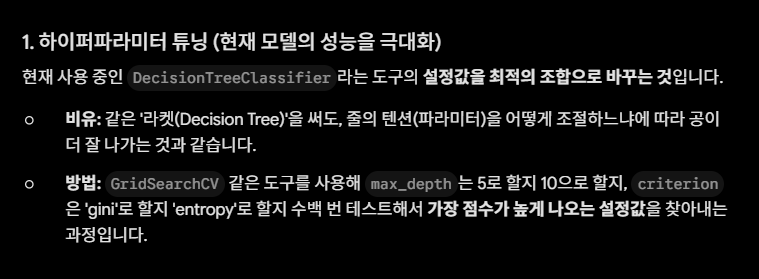

####  - 최적 파라미터 찾기 - 1

In [51]:
from sklearn.model_selection import GridSearchCV

In [52]:
# 결정 트리의 최대 깊이(max_depth)를 여러 값으로 바꿔가며 
# 교차 검증을 통해 가장 성능이 좋은 모델을 자동으로 찾는 과정
# depth가: 작으면 → 단순 → 과소적합 / 크면 → 복잡 → 과적합
# 트리의 질문 횟수를 바꿔가며 언제 성능이 가장 좋아지는지 확인
params = {
    'max_depth' : [6, 8, 10, 11, 16, 20, 24]
}

grid_cv = GridSearchCV(dt_HAR, # 기본 결정 트리 모델
                       param_grid = params, # 실험할 하이퍼파라미터 목록
                       scoring ='accuracy', # 성능 평가 기준
                       #4개를 학습으로 사용하고 1개는 평가로 사용한다.
                       cv = 5, # 5-fold 교차 검증
                       return_train_score = True) 
# 학습 정확도(train score)도 함께 저장 -> 과적합 여부 시각적으로 확인 가능
grid_cv.fit(X_train, Y_train); # 모델 학습 실행

In [53]:
cv_results_df = pd.DataFrame(grid_cv.cv_results_)
cv_results_df[['param_max_depth', 'mean_test_score', 'mean_train_score']]

,param_max_depth,mean_test_score,mean_train_score
0,6,0.850791,0.944879
1,8,0.851069,0.982692
2,10,0.851209,0.993403
3,11,0.849984,0.995681
4,16,0.851344,0.999660
5,20,0.850800,0.999966
6,24,0.849440,1.000000


In [54]:
# grid_cv.best_score_ : GridSearchCV가 찾은 최고 성능 점수 / grid_cv.best_params_ : 최고 성능을 낸 하이퍼파라미터 조합
print('최고 평균 정확도: {0:.4f}, 최적 하이퍼 매개변수: {1}'.format(grid_cv.best_score_, grid_cv.best_params_))

최고 평균 정확도: 0.8513, 최적 하이퍼 매개변수: {'max_depth': 16}


#### - 최적 파라미터 찾기 - 2

In [ ]:
params = {
    'max_depth' : [8, 16, 20],
    'min_samples_split' : [8, 16, 24]
}

grid_cv = GridSearchCV(dt_HAR, 
                       param_grid = params, 
                       scoring ='accuracy', 
                       cv = 5, 
                       return_train_score = True)
grid_cv.fit(X_train, Y_train)

In [ ]:
cv_results_df = pd.DataFrame(grid_cv.cv_results_)
cv_results_df[['param_max_depth', 'param_min_samples_split', 'mean_test_score', 'mean_train_score']]

,param_max_depth,param_min_samples_split,mean_test_score,mean_train_score
0,8,8,0.852023,0.981468
1,8,16,0.854879,0.979836
2,8,24,0.851342,0.978237
3,16,8,0.844136,0.994457
4,16,16,0.847127,0.990479
5,16,24,0.849439,0.986772
6,20,8,0.846040,0.994491
7,20,16,0.848624,0.990479
8,20,24,0.849167,0.986772


In [ ]:
print('최고 평균 정확도: {0:.4f}, 최적 하이퍼 매개변수: {1}'.format(grid_cv.best_score_, grid_cv.best_params_))

최고 평균 정확도: 0.8549, 최적 하이퍼 매개변수: {'max_depth': 8, 'min_samples_split': 16}


In [ ]:
best_dt_HAR = grid_cv.best_estimator_
#가장 값이 좋았던 도구를 가져온다
best_Y_predict = best_dt_HAR.predict(X_test)
#최고의 도구로 테스트를 돌린다
best_accuracy = accuracy_score(Y_test, best_Y_predict)
#그 예측값이 실제 정답과 얼마나 일치하는지 계산한다.
print('best 결정 트리 예측 정확도: {0:.4f}'.format(best_accuracy))

best 결정 트리 예측 정확도: 0.8717


#### *  중요 피처 확인하기

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
feature_importance_values = best_dt_HAR.feature_importances_
feature_importance_values_s = pd.Series(feature_importance_values, 
                                        index = X_train.columns)

In [ ]:
feature_top10 = feature_importance_values_s.sort_values(ascending = False)[:10]

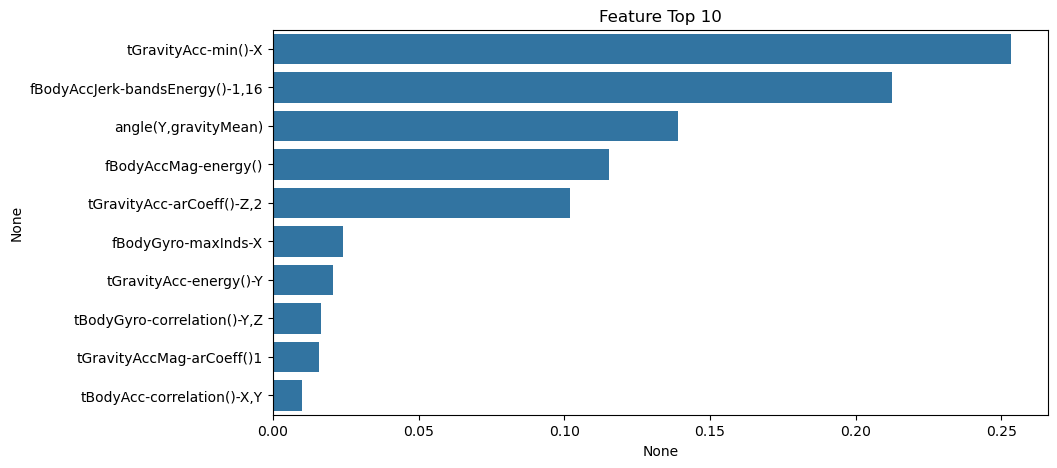

In [ ]:
plt.figure(figsize = (10, 5))
plt.title('Feature Top 10')
sns.barplot(x = feature_top10, y = feature_top10.index)
plt.show()

# 6. 결과 시각화

### 1) graphviz 패키지 다운로드 및 설치
####  - https://graphviz.org/download/에서 graphviz-2.49.3 (64-bit) EXE installer[sha256]을 다운로드하여 설치하기

### 2) graphviz를 파이썬에서 사용하기 위해 파이썬 래퍼 모듈 설치

In [ ]:
! pip install graphviz

### 3) 결정트리 시각화 파일을 생성하기 위해 export_graphviz를 임포트

In [ ]:
from sklearn.tree import export_graphviz

#export_graphviz()의 호출 결과로 out_file로 지정된 tree.dot 파일 생성
export_graphviz(best_dt_HAR, out_file = "./11장_data/tree.dot", class_names = label_name, feature_names = feature_name, impurity = True, filled = True)

### 4) 결정트리 시각화 파일을 읽어서 graphviz로 시각화 출력

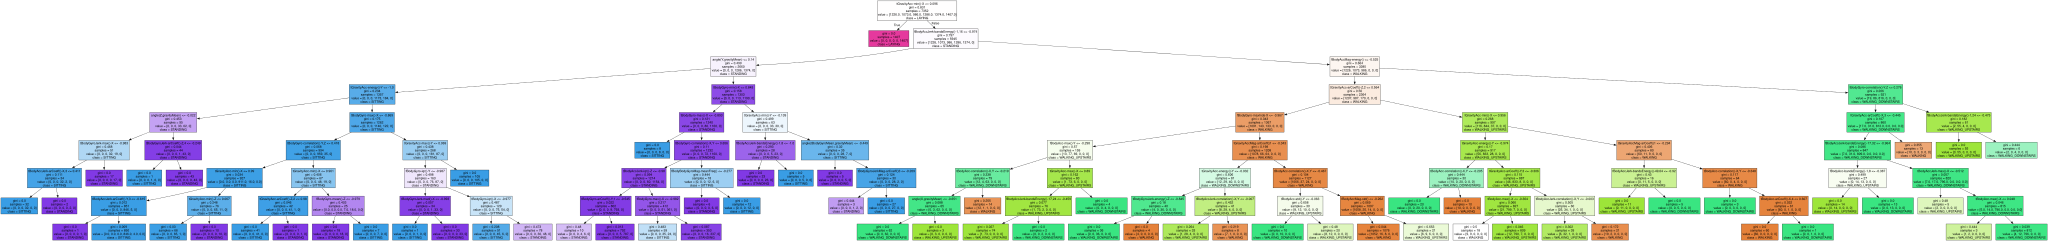

In [ ]:
import graphviz

#위에서 생성된 tree.dot 파일을 Graphviz가 읽어서 시각화
with open("./11장_data/tree.dot") as f:
    dot_graph = f.read()
    
graphviz.Source(dot_graph)

In [ ]:
#루트에서 tGravityAcc-min()-X <= 0.096을 기준으로 나누기 시작한다.
#true false로 나뉘고 root에서 true로 나온값은 gini가 0이므로 모두 하나의 클래스로 이루어져있다.
#max_depth를 5로 설정했기에 리프 노드에는 다양한 gini값을 가지고 있는것을 확인하였다.